# TOP 150 AL COLUMNS - MASTER panel

In [18]:
# ═══════════════════════════════════════════════════════
# MASTER PANEL — Final Model Training
# ═══════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (f1_score, matthews_corrcoef, roc_auc_score,
                             classification_report, confusion_matrix, 
                             ConfusionMatrixDisplay)
from imblearn.under_sampling import RandomUnderSampler
import joblib
import warnings
warnings.filterwarnings('ignore')

In [19]:
# ── Load data ──
MASTER_PATH = r"C:\Users\Sedra\Downloads\YARISMA_TRAIN_MASTER (1).csv"
PANEL = "MASTER"

df = pd.read_csv(MASTER_PATH)
y = df['Label']
print(f"Loaded {PANEL}: {len(df)} rows")
print(f"Pathogenic (1): {(y==1).sum()} | Benign (0): {(y==0).sum()}")


Loaded MASTER: 2931 rows
Pathogenic (1): 2149 | Benign (0): 782


In [20]:
# ── Feature column groups ──
al_cols  = [c for c in df.columns if c.startswith('AL_')]
ek_cols  = [c for c in df.columns if c.startswith('EK_')]
cat_cols = [c for c in df.columns if c.startswith('CAT_')]
aa_cols  = [c for c in df.columns if c.startswith('AA_')]

# ── Feature builder function ──
def build_features(dataframe, al_to_keep=None):
    feats = pd.DataFrame(index=dataframe.index)
    feats['al_missing_ratio'] = dataframe[al_cols].isna().mean(axis=1)
    al_use = al_to_keep if al_to_keep is not None else al_cols
    feats = pd.concat([feats, dataframe[al_use].fillna(0)], axis=1)
    ek_filled = dataframe[ek_cols].copy()
    for col in ek_cols:
        ek_filled[col] = ek_filled[col].fillna(ek_filled[col].median())
    feats = pd.concat([feats, ek_filled], axis=1)
    cat_encoded = pd.get_dummies(dataframe[cat_cols + aa_cols])
    feats = pd.concat([feats, cat_encoded], axis=1)
    feats = feats.replace([np.inf, -np.inf], np.nan).fillna(0).astype(float)
    return feats

In [21]:
# ── Step 1: Find top AL_ columns ──
print("\nStep 1/4: Finding most important AL_ columns...")
X_full = build_features(df)
X_bal_sel, y_bal_sel = RandomUnderSampler(random_state=42).fit_resample(X_full, y)
quick_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
quick_rf.fit(X_bal_sel, y_bal_sel)
importances = pd.Series(quick_rf.feature_importances_, index=X_full.columns)
top_150 = importances.nlargest(150).index.tolist()
top_al_cols = [c for c in top_150 if c in al_cols]
print(f"  → Keeping {len(top_al_cols)} AL_ columns out of {len(al_cols)}")

# ── Step 2: Build final feature matrix ──
print("\nStep 2/4: Building feature matrix...")
X = build_features(df, al_to_keep=top_al_cols)
print(f"  → {X.shape[1]} features total")




Step 1/4: Finding most important AL_ columns...
  → Keeping 129 AL_ columns out of 334

Step 2/4: Building feature matrix...
  → 243 features total


In [22]:
# ── Step 3: Cross-validation ──
print("\nStep 3/4: Cross-validation (5 folds)...")
models = {
    'ExtraTrees': ExtraTreesClassifier(
        n_estimators=300, max_depth=30,
        class_weight='balanced', random_state=42, n_jobs=-1),
    'RandomForest': RandomForestClassifier(
        n_estimators=300, max_depth=30,
        class_weight='balanced', random_state=42, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, clf in models.items():
    f1s, mccs, aucs = [], [], []
    for fold, (tr_idx, val_idx) in enumerate(cv.split(X, y)):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        X_tr_bal, y_tr_bal = RandomUnderSampler(
            random_state=fold).fit_resample(X_tr, y_tr)
        clf.fit(X_tr_bal, y_tr_bal)
        y_pred = clf.predict(X_val)
        y_prob = clf.predict_proba(X_val)[:, 1]

        # ✅ CHANGE 1: binary F1 (pos_label=1 = Pathogenic)
        f1s.append(f1_score(y_val, y_pred, pos_label=1))
        mccs.append(matthews_corrcoef(y_val, y_pred))
        aucs.append(roc_auc_score(y_val, y_prob))

    results[name] = {
        'F1': np.mean(f1s), 'MCC': np.mean(mccs), 'AUC': np.mean(aucs)}
    print(f"  {name}: F1={results[name]['F1']:.4f} | "
          f"MCC={results[name]['MCC']:.4f} | AUC={results[name]['AUC']:.4f}")

best_name = max(results, key=lambda k: results[k]['F1'])
print(f"\n  → Best model: {best_name}")


Step 3/4: Cross-validation (5 folds)...
  ExtraTrees: F1=0.8047 | MCC=0.4760 | AUC=0.8410
  RandomForest: F1=0.8338 | MCC=0.5055 | AUC=0.8470

  → Best model: RandomForest


In [23]:
# ── Step 4: Threshold tuning on hold-out ──
print("\nStep 4/4: Tuning classification threshold...")
X_tr2, X_hold, y_tr2, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=99)
X_tr2_bal, y_tr2_bal = RandomUnderSampler(
    random_state=42).fit_resample(X_tr2, y_tr2)

best_clf = models[best_name]
best_clf.fit(X_tr2_bal, y_tr2_bal)
probs = best_clf.predict_proba(X_hold)[:, 1]

best_thresh, best_f1 = 0.5, 0.0
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)

    # ✅ CHANGE 2: binary F1 in threshold tuning too
    score = f1_score(y_hold, preds_t, pos_label=1)
    if score > best_f1:
        best_f1, best_thresh = score, t

print(f"  → Best threshold: {best_thresh:.2f} | F1 (Pathogenic): {best_f1:.4f}")
y_final = (probs >= best_thresh).astype(int)


Step 4/4: Tuning classification threshold...
  → Best threshold: 0.32 | F1 (Pathogenic): 0.8862



─── Competition Metrics on Hold-out Set ───
  TP (Doğru Pozitif)  : 409
  FP (Yanlış Pozitif) : 84
  FN (Yanlış Negatif) : 21
  TN (Doğru Negatif)  : 73
  F1 Score            : 0.8862
  MCC                 : 0.5023
  Precision           : 0.8296
  Recall (Sensitivity): 0.9512

                precision    recall  f1-score   support

    Benign (0)       0.78      0.46      0.58       157
Pathogenic (1)       0.83      0.95      0.89       430

      accuracy                           0.82       587
     macro avg       0.80      0.71      0.73       587
  weighted avg       0.82      0.82      0.80       587



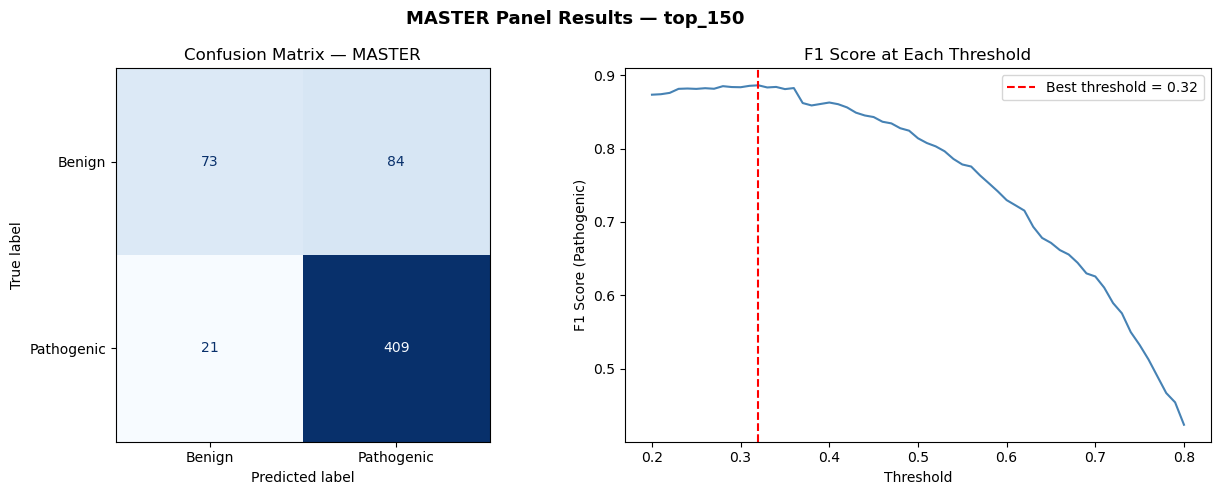

   Algorithm  : RandomForest
   Features   : 243
   Threshold  : 0.32
   F1 Score   : 0.8862


In [26]:
# ✅ CHANGE 3: Show TP/FP/FN/TN as the competition describes
tn, fp, fn, tp = confusion_matrix(y_hold, y_final).ravel()

print("\n─── Competition Metrics on Hold-out Set ───")
print(f"  TP (Doğru Pozitif)  : {tp}")
print(f"  FP (Yanlış Pozitif) : {fp}")
print(f"  FN (Yanlış Negatif) : {fn}")
print(f"  TN (Doğru Negatif)  : {tn}")
print(f"  F1 Score            : {f1_score(y_hold, y_final, pos_label=1):.4f}")
print(f"  MCC                 : {matthews_corrcoef(y_hold, y_final):.4f}")
print(f"  Precision           : {tp/(tp+fp):.4f}")
print(f"  Recall (Sensitivity): {tp/(tp+fn):.4f}")
print()
print(classification_report(y_hold, y_final,
      target_names=['Benign (0)', 'Pathogenic (1)']))

# ── Confusion matrix ──
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_hold, y_final)
ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Pathogenic']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix — {PANEL}')

# ✅ Threshold sweep also uses binary F1 now
f1_by_thresh = []
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    f1_by_thresh.append(f1_score(y_hold, preds_t, pos_label=1))
axes[1].plot(np.arange(0.20, 0.80, 0.01), f1_by_thresh, color='steelblue')
axes[1].axvline(x=best_thresh, color='red', linestyle='--',
                label=f'Best threshold = {best_thresh:.2f}')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('F1 Score (Pathogenic)')
axes[1].set_title('F1 Score at Each Threshold')
axes[1].legend()

plt.suptitle(f'{PANEL} Panel Results — top_150', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

''''# ── Retrain on full data and save ──
X_bal_final, y_bal_final = RandomUnderSampler(
    random_state=42).fit_resample(X, y)
best_clf.fit(X_bal_final, y_bal_final)

joblib.dump({
    'model': best_clf,
    'feature_cols': list(X.columns),
    'al_cols_used': top_al_cols,
    'threshold': best_thresh,
    'panel': PANEL
}, f'{PANEL}_model.pkl')

print(f"\n✅ {PANEL} model saved as {PANEL}_model.pkl")'''
print(f"   Algorithm  : {best_name}")
print(f"   Features   : {X.shape[1]}")
print(f"   Threshold  : {best_thresh:.2f}")
print(f"   F1 Score   : {best_f1:.4f}")

# TOP 125 AL COLUMNS - MASTER panel - just for comparing in the report

Loaded MASTER: 2931 rows
Pathogenic (1): 2149 | Benign (0): 782

Step 1/4: Finding most important AL_ columns...
  → Keeping 111 AL_ columns out of 334

Step 2/4: Building feature matrix...
  → 225 features total

Step 3/4: Cross-validation (5 folds)...
  ExtraTrees: F1=0.7985 | MCC=0.4573 | AUC=0.8364
  RandomForest: F1=0.8336 | MCC=0.4999 | AUC=0.8445

  → Best model: RandomForest

Step 4/4: Tuning classification threshold...
  → Best threshold: 0.36 | F1 (Pathogenic): 0.8830

─── Competition Metrics on Hold-out Set ───
  TP (Doğru Pozitif)  : 400
  FP (Yanlış Pozitif) : 76
  FN (Yanlış Negatif) : 30
  TN (Doğru Negatif)  : 81
  F1 Score            : 0.8830
  MCC                 : 0.5043
  Precision           : 0.8403
  Recall (Sensitivity): 0.9302

                precision    recall  f1-score   support

    Benign (0)       0.73      0.52      0.60       157
Pathogenic (1)       0.84      0.93      0.88       430

      accuracy                           0.82       587
     macro a

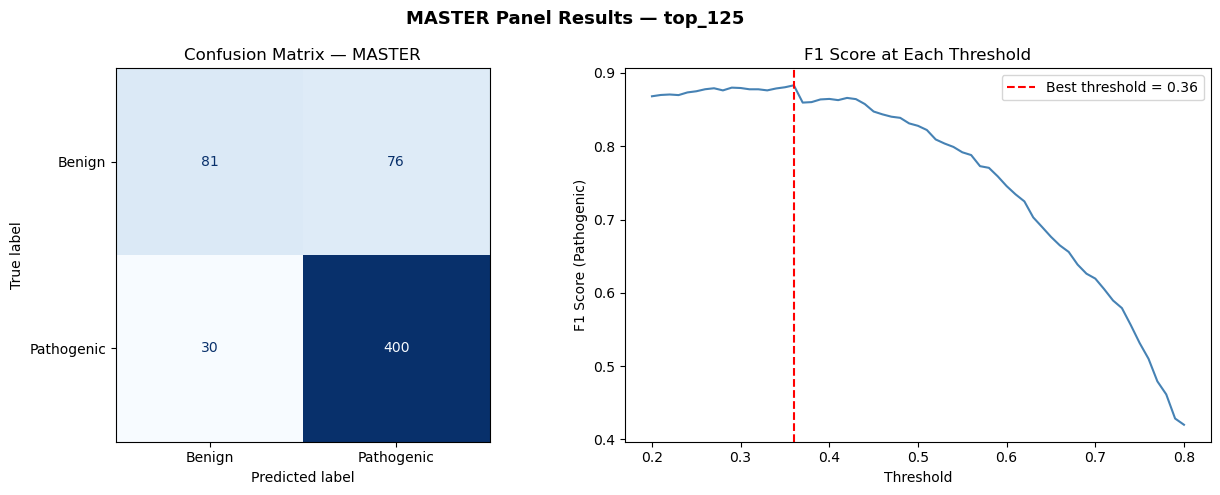

   Algorithm  : RandomForest
   Features   : 225
   Threshold  : 0.36
   F1 Score   : 0.8830


In [3]:
# ═══════════════════════════════════════════════════════
# MASTER PANEL — Final Model Training
# ═══════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (f1_score, matthews_corrcoef, roc_auc_score,
                             classification_report, confusion_matrix, 
                             ConfusionMatrixDisplay)
from imblearn.under_sampling import RandomUnderSampler
import joblib
import warnings
warnings.filterwarnings('ignore')

# ── Load data ──
MASTER_PATH = r"C:\Users\Sedra\Downloads\YARISMA_TRAIN_MASTER (1).csv"
PANEL = "MASTER"

df = pd.read_csv(MASTER_PATH)
y = df['Label']
print(f"Loaded {PANEL}: {len(df)} rows")
print(f"Pathogenic (1): {(y==1).sum()} | Benign (0): {(y==0).sum()}")

# ── Feature column groups ──
al_cols  = [c for c in df.columns if c.startswith('AL_')]
ek_cols  = [c for c in df.columns if c.startswith('EK_')]
cat_cols = [c for c in df.columns if c.startswith('CAT_')]
aa_cols  = [c for c in df.columns if c.startswith('AA_')]

# ── Feature builder function ──
def build_features(dataframe, al_to_keep=None):
    feats = pd.DataFrame(index=dataframe.index)
    feats['al_missing_ratio'] = dataframe[al_cols].isna().mean(axis=1)
    al_use = al_to_keep if al_to_keep is not None else al_cols
    feats = pd.concat([feats, dataframe[al_use].fillna(0)], axis=1)
    ek_filled = dataframe[ek_cols].copy()
    for col in ek_cols:
        ek_filled[col] = ek_filled[col].fillna(ek_filled[col].median())
    feats = pd.concat([feats, ek_filled], axis=1)
    cat_encoded = pd.get_dummies(dataframe[cat_cols + aa_cols])
    feats = pd.concat([feats, cat_encoded], axis=1)
    feats = feats.replace([np.inf, -np.inf], np.nan).fillna(0).astype(float)
    return feats

# ── Step 1: Find top AL_ columns ──
print("\nStep 1/4: Finding most important AL_ columns...")
X_full = build_features(df)
X_bal_sel, y_bal_sel = RandomUnderSampler(random_state=42).fit_resample(X_full, y)
quick_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
quick_rf.fit(X_bal_sel, y_bal_sel)
importances = pd.Series(quick_rf.feature_importances_, index=X_full.columns)
top_125 = importances.nlargest(125).index.tolist()
top_al_cols = [c for c in top_125 if c in al_cols]
print(f"  → Keeping {len(top_al_cols)} AL_ columns out of {len(al_cols)}")

# ── Step 2: Build final feature matrix ──
print("\nStep 2/4: Building feature matrix...")
X = build_features(df, al_to_keep=top_al_cols)
print(f"  → {X.shape[1]} features total")

# ── Step 3: Cross-validation ──
print("\nStep 3/4: Cross-validation (5 folds)...")
models = {
    'ExtraTrees': ExtraTreesClassifier(
        n_estimators=300, max_depth=30,
        class_weight='balanced', random_state=42, n_jobs=-1),
    'RandomForest': RandomForestClassifier(
        n_estimators=300, max_depth=30,
        class_weight='balanced', random_state=42, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, clf in models.items():
    f1s, mccs, aucs = [], [], []
    for fold, (tr_idx, val_idx) in enumerate(cv.split(X, y)):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        X_tr_bal, y_tr_bal = RandomUnderSampler(
            random_state=fold).fit_resample(X_tr, y_tr)
        clf.fit(X_tr_bal, y_tr_bal)
        y_pred = clf.predict(X_val)
        y_prob = clf.predict_proba(X_val)[:, 1]

        # ✅ CHANGE 1: binary F1 (pos_label=1 = Pathogenic)
        f1s.append(f1_score(y_val, y_pred, pos_label=1))
        mccs.append(matthews_corrcoef(y_val, y_pred))
        aucs.append(roc_auc_score(y_val, y_prob))

    results[name] = {
        'F1': np.mean(f1s), 'MCC': np.mean(mccs), 'AUC': np.mean(aucs)}
    print(f"  {name}: F1={results[name]['F1']:.4f} | "
          f"MCC={results[name]['MCC']:.4f} | AUC={results[name]['AUC']:.4f}")

best_name = max(results, key=lambda k: results[k]['F1'])
print(f"\n  → Best model: {best_name}")

# ── Step 4: Threshold tuning on hold-out ──
print("\nStep 4/4: Tuning classification threshold...")
X_tr2, X_hold, y_tr2, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=99)
X_tr2_bal, y_tr2_bal = RandomUnderSampler(
    random_state=42).fit_resample(X_tr2, y_tr2)

best_clf = models[best_name]
best_clf.fit(X_tr2_bal, y_tr2_bal)
probs = best_clf.predict_proba(X_hold)[:, 1]

best_thresh, best_f1 = 0.5, 0.0
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)

    # ✅ CHANGE 2: binary F1 in threshold tuning too
    score = f1_score(y_hold, preds_t, pos_label=1)
    if score > best_f1:
        best_f1, best_thresh = score, t

print(f"  → Best threshold: {best_thresh:.2f} | F1 (Pathogenic): {best_f1:.4f}")
y_final = (probs >= best_thresh).astype(int)

# ✅ CHANGE 3: Show TP/FP/FN/TN as the competition describes
tn, fp, fn, tp = confusion_matrix(y_hold, y_final).ravel()

print("\n─── Competition Metrics on Hold-out Set ───")
print(f"  TP (Doğru Pozitif)  : {tp}")
print(f"  FP (Yanlış Pozitif) : {fp}")
print(f"  FN (Yanlış Negatif) : {fn}")
print(f"  TN (Doğru Negatif)  : {tn}")
print(f"  F1 Score            : {f1_score(y_hold, y_final, pos_label=1):.4f}")
print(f"  MCC                 : {matthews_corrcoef(y_hold, y_final):.4f}")
print(f"  Precision           : {tp/(tp+fp):.4f}")
print(f"  Recall (Sensitivity): {tp/(tp+fn):.4f}")
print()
print(classification_report(y_hold, y_final,
      target_names=['Benign (0)', 'Pathogenic (1)']))

# ── Confusion matrix ──
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_hold, y_final)
ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Pathogenic']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix — {PANEL}')

# ✅ Threshold sweep also uses binary F1 now
f1_by_thresh = []
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    f1_by_thresh.append(f1_score(y_hold, preds_t, pos_label=1))
axes[1].plot(np.arange(0.20, 0.80, 0.01), f1_by_thresh, color='steelblue')
axes[1].axvline(x=best_thresh, color='red', linestyle='--',
                label=f'Best threshold = {best_thresh:.2f}')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('F1 Score (Pathogenic)')
axes[1].set_title('F1 Score at Each Threshold')
axes[1].legend()

plt.suptitle(f'{PANEL} Panel Results — top_125', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

''''# ── Retrain on full data and save ──
X_bal_final, y_bal_final = RandomUnderSampler(
    random_state=42).fit_resample(X, y)
best_clf.fit(X_bal_final, y_bal_final)

joblib.dump({
    'model': best_clf,
    'feature_cols': list(X.columns),
    'al_cols_used': top_al_cols,
    'threshold': best_thresh,
    'panel': PANEL
}, f'{PANEL}_model.pkl')

print(f"\n✅ {PANEL} model saved as {PANEL}_model.pkl")'''
print(f"   Algorithm  : {best_name}")
print(f"   Features   : {X.shape[1]}")
print(f"   Threshold  : {best_thresh:.2f}")
print(f"   F1 Score   : {best_f1:.4f}")

Loaded KANSER: 388 rows
Pathogenic (1): 268 | Benign (0): 120

Step 1/4: Finding most important AL_ columns...
  → Keeping 122 AL_ columns out of 334

Step 2/4: Building feature matrix...
  → 224 features total

Step 3/4: Cross-validation (5 folds)...
  ExtraTrees: F1=0.8631 | MCC=0.6222 | AUC=0.9063
  RandomForest: F1=0.8706 | MCC=0.6455 | AUC=0.9030

  → Best model: RandomForest

Step 4/4: Tuning classification threshold...
  → Best threshold: 0.20 | F1 (Pathogenic): 0.9231

─── Competition Metrics on Hold-out Set ───
  TP (Doğru Pozitif)  : 54
  FP (Yanlış Pozitif) : 9
  FN (Yanlış Negatif) : 0
  TN (Doğru Negatif)  : 15
  F1 Score            : 0.9231
  MCC                 : 0.7319
  Precision           : 0.8571
  Recall (Sensitivity): 1.0000

                precision    recall  f1-score   support

    Benign (0)       1.00      0.62      0.77        24
Pathogenic (1)       0.86      1.00      0.92        54

      accuracy                           0.88        78
     macro avg   

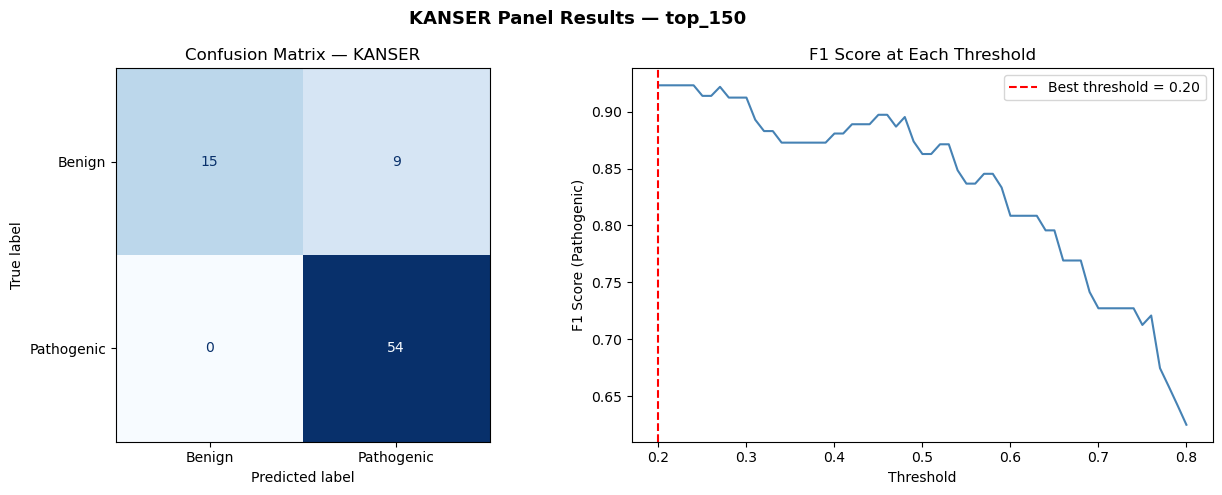

   Algorithm  : RandomForest
   Features   : 224
   Threshold  : 0.20
   F1 Score   : 0.9231


In [7]:
# ═══════════════════════════════════════════════════════
# KANSER PANEL — Final Model Training
# ═══════════════════════════════════════════════════════

KANSER_PATH = r"C:\Users\Sedra\Downloads\YARISMA_TRAIN_KANSER.csv"   # ← change if needed
PANEL = "KANSER"

df = pd.read_csv(KANSER_PATH)
y = df['Label']
print(f"Loaded {PANEL}: {len(df)} rows")
print(f"Pathogenic (1): {(y==1).sum()} | Benign (0): {(y==0).sum()}")

# ── Step 1: Find top AL_ columns ──
print("\nStep 1/4: Finding most important AL_ columns...")
X_full = build_features(df)
X_bal_sel, y_bal_sel = RandomUnderSampler(random_state=42).fit_resample(X_full, y)
quick_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
quick_rf.fit(X_bal_sel, y_bal_sel)
importances = pd.Series(quick_rf.feature_importances_, index=X_full.columns)
top_150 = importances.nlargest(150).index.tolist()
top_al_cols = [c for c in top_150 if c in al_cols]
print(f"  → Keeping {len(top_al_cols)} AL_ columns out of {len(al_cols)}")

# ── Step 2: Build feature matrix ──
print("\nStep 2/4: Building feature matrix...")
X = build_features(df, al_to_keep=top_al_cols)
print(f"  → {X.shape[1]} features total")

# ── Step 3: Cross-validation ──
print("\nStep 3/4: Cross-validation (5 folds)...")
models = {
    'ExtraTrees': ExtraTreesClassifier(
        n_estimators=300, max_depth=30,
        class_weight='balanced', random_state=42, n_jobs=-1),
    'RandomForest': RandomForestClassifier(
        n_estimators=300, max_depth=30,
        class_weight='balanced', random_state=42, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, clf in models.items():
    f1s, mccs, aucs = [], [], []
    for fold, (tr_idx, val_idx) in enumerate(cv.split(X, y)):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        X_tr_bal, y_tr_bal = RandomUnderSampler(
            random_state=fold).fit_resample(X_tr, y_tr)
        clf.fit(X_tr_bal, y_tr_bal)
        y_pred = clf.predict(X_val)
        y_prob = clf.predict_proba(X_val)[:, 1]
        f1s.append(f1_score(y_val, y_pred, pos_label=1))
        mccs.append(matthews_corrcoef(y_val, y_pred))
        aucs.append(roc_auc_score(y_val, y_prob))
    results[name] = {
        'F1': np.mean(f1s), 'MCC': np.mean(mccs), 'AUC': np.mean(aucs)}
    print(f"  {name}: F1={results[name]['F1']:.4f} | "
          f"MCC={results[name]['MCC']:.4f} | AUC={results[name]['AUC']:.4f}")

best_name = max(results, key=lambda k: results[k]['F1'])
print(f"\n  → Best model: {best_name}")

# ── Step 4: Threshold tuning ──
print("\nStep 4/4: Tuning classification threshold...")
X_tr2, X_hold, y_tr2, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=99)
X_tr2_bal, y_tr2_bal = RandomUnderSampler(
    random_state=42).fit_resample(X_tr2, y_tr2)

best_clf = models[best_name]
best_clf.fit(X_tr2_bal, y_tr2_bal)
probs = best_clf.predict_proba(X_hold)[:, 1]

best_thresh, best_f1 = 0.5, 0.0
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    score = f1_score(y_hold, preds_t, pos_label=1)
    if score > best_f1:
        best_f1, best_thresh = score, t

print(f"  → Best threshold: {best_thresh:.2f} | F1 (Pathogenic): {best_f1:.4f}")
y_final = (probs >= best_thresh).astype(int)

tn, fp, fn, tp = confusion_matrix(y_hold, y_final).ravel()
print("\n─── Competition Metrics on Hold-out Set ───")
print(f"  TP (Doğru Pozitif)  : {tp}")
print(f"  FP (Yanlış Pozitif) : {fp}")
print(f"  FN (Yanlış Negatif) : {fn}")
print(f"  TN (Doğru Negatif)  : {tn}")
print(f"  F1 Score            : {f1_score(y_hold, y_final, pos_label=1):.4f}")
print(f"  MCC                 : {matthews_corrcoef(y_hold, y_final):.4f}")
print(f"  Precision           : {tp/(tp+fp):.4f}")
print(f"  Recall (Sensitivity): {tp/(tp+fn):.4f}")
print()
print(classification_report(y_hold, y_final,
      target_names=['Benign (0)', 'Pathogenic (1)']))

# ── Plots ──
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_hold, y_final)
ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Pathogenic']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix — {PANEL}')
f1_by_thresh = []
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    f1_by_thresh.append(f1_score(y_hold, preds_t, pos_label=1))
axes[1].plot(np.arange(0.20, 0.80, 0.01), f1_by_thresh, color='steelblue')
axes[1].axvline(x=best_thresh, color='red', linestyle='--',
                label=f'Best threshold = {best_thresh:.2f}')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('F1 Score (Pathogenic)')
axes[1].set_title('F1 Score at Each Threshold')
axes[1].legend()
plt.suptitle(f'{PANEL} Panel Results — top_150', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

''''# ── Save ──
X_bal_final, y_bal_final = RandomUnderSampler(
    random_state=42).fit_resample(X, y)
best_clf.fit(X_bal_final, y_bal_final)
joblib.dump({
    'model': best_clf,
    'feature_cols': list(X.columns),
    'al_cols_used': top_al_cols,
    'threshold': best_thresh,
    'panel': PANEL
}, f'{PANEL}_model.pkl')

print(f"\n✅ {PANEL} model saved as {PANEL}_model.pkl")'''
print(f"   Algorithm  : {best_name}")
print(f"   Features   : {X.shape[1]}")
print(f"   Threshold  : {best_thresh:.2f}")
print(f"   F1 Score   : {best_f1:.4f}")

# Kanser panel model

Loaded KANSER: 388 rows
Pathogenic (1): 268 | Benign (0): 120

Step 1/4: Finding most important AL_ columns...
  → Keeping 122 AL_ columns out of 334

Step 2/4: Building feature matrix...
  → 224 features total

Step 3/4: Cross-validation (5 folds)...
  ExtraTrees: F1=0.8631 | MCC=0.6222 | AUC=0.9063
  RandomForest: F1=0.8706 | MCC=0.6455 | AUC=0.9030

  → Best model: RandomForest
  → Best threshold: 0.20 | MCC: 0.7319

─── Competition Metrics on Hold-out Set ───
  TP (Doğru Pozitif)  : 54
  FP (Yanlış Pozitif) : 9
  FN (Yanlış Negatif) : 0
  TN (Doğru Negatif)  : 15
  F1 Score            : 0.9231
  MCC                 : 0.7319
  Precision           : 0.8571
  Recall (Sensitivity): 1.0000

                precision    recall  f1-score   support

    Benign (0)       1.00      0.62      0.77        24
Pathogenic (1)       0.86      1.00      0.92        54

      accuracy                           0.88        78
     macro avg       0.93      0.81      0.85        78
  weighted avg     

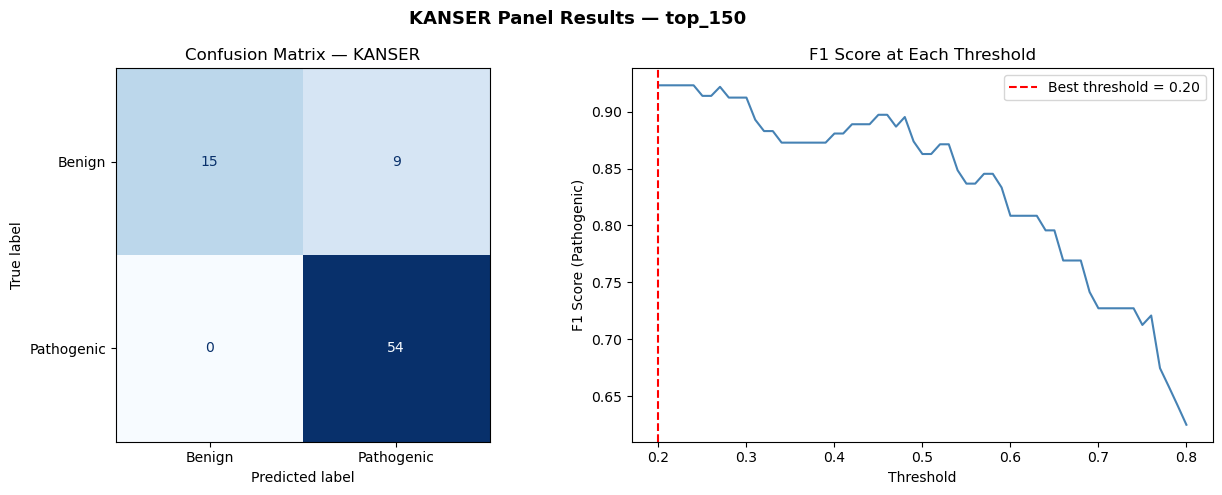

   Algorithm  : RandomForest
   Features   : 224
   Threshold  : 0.20
   F1 Score   : 0.9231


In [9]:
# ═══════════════════════════════════════════════════════
# KANSER PANEL — Final Model Training
# ═══════════════════════════════════════════════════════

KANSER_PATH = r"C:\Users\Sedra\Downloads\YARISMA_TRAIN_KANSER.csv"   # ← change if needed
PANEL = "KANSER"

df = pd.read_csv(KANSER_PATH)
y = df['Label']
print(f"Loaded {PANEL}: {len(df)} rows")
print(f"Pathogenic (1): {(y==1).sum()} | Benign (0): {(y==0).sum()}")

# ── Step 1: Find top AL_ columns ──
print("\nStep 1/4: Finding most important AL_ columns...")
X_full = build_features(df)
X_bal_sel, y_bal_sel = RandomUnderSampler(random_state=42).fit_resample(X_full, y)
quick_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
quick_rf.fit(X_bal_sel, y_bal_sel)
importances = pd.Series(quick_rf.feature_importances_, index=X_full.columns)
top_150 = importances.nlargest(150).index.tolist()
top_al_cols = [c for c in top_150 if c in al_cols]
print(f"  → Keeping {len(top_al_cols)} AL_ columns out of {len(al_cols)}")

# ── Step 2: Build feature matrix ──
print("\nStep 2/4: Building feature matrix...")
X = build_features(df, al_to_keep=top_al_cols)
print(f"  → {X.shape[1]} features total")

# ── Step 3: Cross-validation ──
print("\nStep 3/4: Cross-validation (5 folds)...")
models = {
    'ExtraTrees': ExtraTreesClassifier(
        n_estimators=300, max_depth=30,
        class_weight='balanced', random_state=42, n_jobs=-1),
    'RandomForest': RandomForestClassifier(
        n_estimators=300, max_depth=30,
        class_weight='balanced', random_state=42, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, clf in models.items():
    f1s, mccs, aucs = [], [], []
    for fold, (tr_idx, val_idx) in enumerate(cv.split(X, y)):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        X_tr_bal, y_tr_bal = RandomUnderSampler(
            random_state=fold).fit_resample(X_tr, y_tr)
        clf.fit(X_tr_bal, y_tr_bal)
        y_pred = clf.predict(X_val)
        y_prob = clf.predict_proba(X_val)[:, 1]
        f1s.append(f1_score(y_val, y_pred, pos_label=1))
        mccs.append(matthews_corrcoef(y_val, y_pred))
        aucs.append(roc_auc_score(y_val, y_prob))
    results[name] = {
        'F1': np.mean(f1s), 'MCC': np.mean(mccs), 'AUC': np.mean(aucs)}
    print(f"  {name}: F1={results[name]['F1']:.4f} | "
          f"MCC={results[name]['MCC']:.4f} | AUC={results[name]['AUC']:.4f}")

best_name = max(results, key=lambda k: results[k]['F1'])
print(f"\n  → Best model: {best_name}")

# ── Step 4: Threshold tuning ──
# ── FIXED Threshold tuning for small panels ──
# Use MCC instead of binary F1 to avoid "predict everything Pathogenic" trap

best_thresh, best_mcc = 0.5, -1.0
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    
    # Skip thresholds where model predicts only one class
    if len(set(preds_t)) < 2:
        continue
        
    mcc_t = matthews_corrcoef(y_hold, preds_t)
    if mcc_t > best_mcc:
        best_mcc, best_thresh = mcc_t, t

print(f"  → Best threshold: {best_thresh:.2f} | MCC: {best_mcc:.4f}")
y_final = (probs >= best_thresh).astype(int)

tn, fp, fn, tp = confusion_matrix(y_hold, y_final).ravel()
print("\n─── Competition Metrics on Hold-out Set ───")
print(f"  TP (Doğru Pozitif)  : {tp}")
print(f"  FP (Yanlış Pozitif) : {fp}")
print(f"  FN (Yanlış Negatif) : {fn}")
print(f"  TN (Doğru Negatif)  : {tn}")
print(f"  F1 Score            : {f1_score(y_hold, y_final, pos_label=1):.4f}")
print(f"  MCC                 : {matthews_corrcoef(y_hold, y_final):.4f}")
print(f"  Precision           : {tp/(tp+fp):.4f}")
print(f"  Recall (Sensitivity): {tp/(tp+fn):.4f}")
print()
print(classification_report(y_hold, y_final,
      target_names=['Benign (0)', 'Pathogenic (1)']))

# ── Plots ──
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_hold, y_final)
ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Pathogenic']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix — {PANEL}')
f1_by_thresh = []
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    f1_by_thresh.append(f1_score(y_hold, preds_t, pos_label=1))
axes[1].plot(np.arange(0.20, 0.80, 0.01), f1_by_thresh, color='steelblue')
axes[1].axvline(x=best_thresh, color='red', linestyle='--',
                label=f'Best threshold = {best_thresh:.2f}')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('F1 Score (Pathogenic)')
axes[1].set_title('F1 Score at Each Threshold')
axes[1].legend()
plt.suptitle(f'{PANEL} Panel Results — top_150', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

''''# ── Save ──
X_bal_final, y_bal_final = RandomUnderSampler(
    random_state=42).fit_resample(X, y)
best_clf.fit(X_bal_final, y_bal_final)
joblib.dump({
    'model': best_clf,
    'feature_cols': list(X.columns),
    'al_cols_used': top_al_cols,
    'threshold': best_thresh,
    'panel': PANEL
}, f'{PANEL}_model.pkl')

print(f"\n✅ {PANEL} model saved as {PANEL}_model.pkl")'''
print(f"   Algorithm  : {best_name}")
print(f"   Features   : {X.shape[1]}")
print(f"   Threshold  : {best_thresh:.2f}")
print(f"   F1 Score   : {best_f1:.4f}")

## PAH Model - Threshold->F1

Loaded PAH: 372 rows
Pathogenic (1): 310 | Benign (0): 62
⚠️  Warning: Only 62 Benign samples — results may be unstable

Step 1/4: Finding most important AL_ columns...
  → Keeping 88 AL_ columns out of 334
  → (Using top 100 — safer for small dataset)

Step 2/4: Building feature matrix...
  → 182 features total

Step 3/4: Cross-validation (3 folds — adjusted for small dataset)...
  ExtraTrees: F1=0.7816 | MCC=0.3092 | AUC=0.7579
  RandomForest: F1=0.7728 | MCC=0.2670 | AUC=0.7679

  → Best model: ExtraTrees

Step 4/4: Tuning classification threshold...
  → Best threshold: 0.27 | F1 (Pathogenic): 0.9091

─── Competition Metrics on Hold-out Set ───
  TP (Doğru Pozitif)  : 60
  FP (Yanlış Pozitif) : 9
  FN (Yanlış Negatif) : 3
  TN (Doğru Negatif)  : 3
  F1 Score            : 0.9091
  MCC                 : 0.2735
  Precision           : 0.8696
  Recall (Sensitivity): 0.9524
⚠️  Hold-out has only ~12 Benign — interpret carefully

                precision    recall  f1-score   support

  

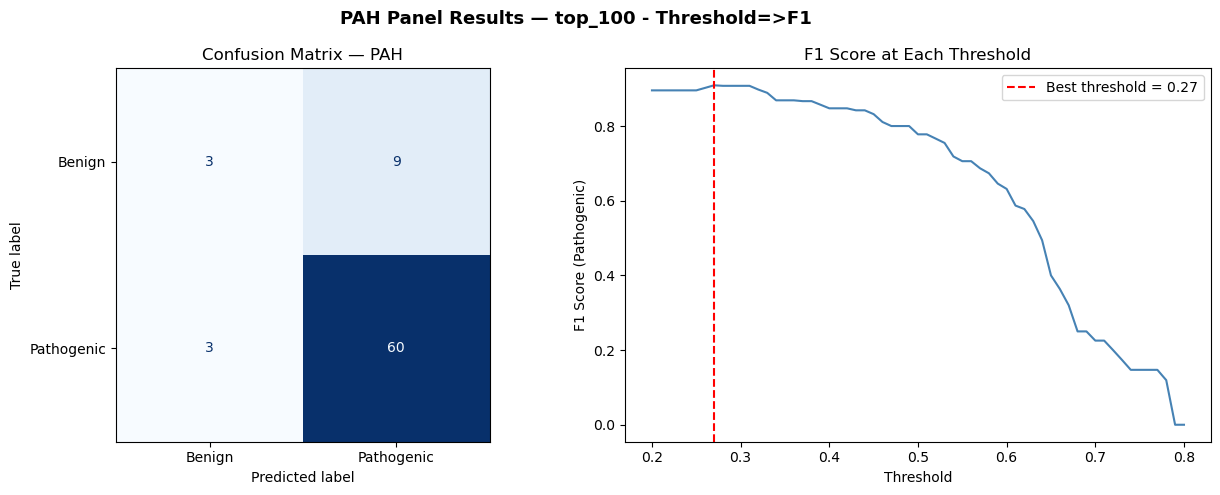

   Algorithm  : ExtraTrees
   Features   : 182
   Threshold  : 0.27
   F1 Score   : 0.9091


In [17]:
# ═══════════════════════════════════════════════════════
# PAH PANEL — Final Model Training
# ═══════════════════════════════════════════════════════

PAH_PATH = r"C:\Users\Sedra\Downloads\YARISMA_TRAIN_PAH.csv"   # ← change if needed
PANEL = "PAH"

df = pd.read_csv(PAH_PATH)
y = df['Label']
print(f"Loaded {PANEL}: {len(df)} rows")
print(f"Pathogenic (1): {(y==1).sum()} | Benign (0): {(y==0).sum()}")
print(f"⚠️  Warning: Only {(y==0).sum()} Benign samples — results may be unstable")

# ── Step 1: Find top AL_ columns ──
print("\nStep 1/4: Finding most important AL_ columns...")
X_full = build_features(df)
X_bal_sel, y_bal_sel = RandomUnderSampler(random_state=42).fit_resample(X_full, y)
quick_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
quick_rf.fit(X_bal_sel, y_bal_sel)
importances = pd.Series(quick_rf.feature_importances_, index=X_full.columns)
top_100 = importances.nlargest(100).index.tolist()
top_al_cols = [c for c in top_100 if c in al_cols]
print(f"  → Keeping {len(top_al_cols)} AL_ columns out of {len(al_cols)}")
print(f"  → (Using top 100 — safer for small dataset)")

# ── Step 2: Build feature matrix ──
print("\nStep 2/4: Building feature matrix...")
X = build_features(df, al_to_keep=top_al_cols)
print(f"  → {X.shape[1]} features total")

# ── Step 3: Cross-validation with 3 folds ──
print("\nStep 3/4: Cross-validation (3 folds — adjusted for small dataset)...")
models = {
    'ExtraTrees': ExtraTreesClassifier(
        n_estimators=300, max_depth=15,
        min_samples_leaf=3,
        class_weight='balanced', random_state=42, n_jobs=-1),
    'RandomForest': RandomForestClassifier(
        n_estimators=300, max_depth=15,
        min_samples_leaf=3,
        class_weight='balanced', random_state=42, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
results = {}

for name, clf in models.items():
    f1s, mccs, aucs = [], [], []
    for fold, (tr_idx, val_idx) in enumerate(cv.split(X, y)):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        X_tr_bal, y_tr_bal = RandomUnderSampler(
            random_state=fold).fit_resample(X_tr, y_tr)
        clf.fit(X_tr_bal, y_tr_bal)
        y_pred = clf.predict(X_val)
        y_prob = clf.predict_proba(X_val)[:, 1]
        f1s.append(f1_score(y_val, y_pred, pos_label=1))
        mccs.append(matthews_corrcoef(y_val, y_pred))
        aucs.append(roc_auc_score(y_val, y_prob))
    results[name] = {
        'F1': np.mean(f1s), 'MCC': np.mean(mccs), 'AUC': np.mean(aucs)}
    print(f"  {name}: F1={results[name]['F1']:.4f} | "
          f"MCC={results[name]['MCC']:.4f} | AUC={results[name]['AUC']:.4f}")

best_name = max(results, key=lambda k: results[k]['F1'])
print(f"\n  → Best model: {best_name}")


# ── Step 4: Threshold tuning ──
print("\nStep 4/4: Tuning classification threshold...")
X_tr2, X_hold, y_tr2, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=99)
X_tr2_bal, y_tr2_bal = RandomUnderSampler(
    random_state=42).fit_resample(X_tr2, y_tr2)

best_clf = models[best_name]
best_clf.fit(X_tr2_bal, y_tr2_bal)
probs = best_clf.predict_proba(X_hold)[:, 1]

best_thresh, best_f1 = 0.5, 0.0
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    score = f1_score(y_hold, preds_t, pos_label=1)
    if score > best_f1:
        best_f1, best_thresh = score, t

print(f"  → Best threshold: {best_thresh:.2f} | F1 (Pathogenic): {best_f1:.4f}")
y_final = (probs >= best_thresh).astype(int)


tn, fp, fn, tp = confusion_matrix(y_hold, y_final).ravel()
print("\n─── Competition Metrics on Hold-out Set ───")
print(f"  TP (Doğru Pozitif)  : {tp}")
print(f"  FP (Yanlış Pozitif) : {fp}")
print(f"  FN (Yanlış Negatif) : {fn}")
print(f"  TN (Doğru Negatif)  : {tn}")
print(f"  F1 Score            : {f1_score(y_hold, y_final, pos_label=1):.4f}")
print(f"  MCC                 : {matthews_corrcoef(y_hold, y_final):.4f}")
print(f"  Precision           : {tp/(tp+fp):.4f}")
print(f"  Recall (Sensitivity): {tp/(tp+fn):.4f}")
print(f"⚠️  Hold-out has only ~{(y_hold==0).sum()} Benign — interpret carefully")
print()
print(classification_report(y_hold, y_final,
      target_names=['Benign (0)', 'Pathogenic (1)']))

# ── Plots ──
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_hold, y_final)
ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Pathogenic']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix — {PANEL}')
f1_by_thresh = []
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    f1_by_thresh.append(f1_score(y_hold, preds_t, pos_label=1))
axes[1].plot(np.arange(0.20, 0.80, 0.01), f1_by_thresh, color='steelblue')
axes[1].axvline(x=best_thresh, color='red', linestyle='--',
                label=f'Best threshold = {best_thresh:.2f}')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('F1 Score (Pathogenic)')
axes[1].set_title('F1 Score at Each Threshold')
axes[1].legend()
plt.suptitle(f'{PANEL} Panel Results — top_100 - Threshold=>F1', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

''''# ── Save ──
X_bal_final, y_bal_final = RandomUnderSampler(
    random_state=42).fit_resample(X, y)
best_clf.fit(X_bal_final, y_bal_final)
joblib.dump({
    'model': best_clf,
    'feature_cols': list(X.columns),
    'al_cols_used': top_al_cols,
    'threshold': best_thresh,
    'panel': PANEL
}, f'{PANEL}_model.pkl')

print(f"\n✅ {PANEL} model saved as {PANEL}_model.pkl")'''
print(f"   Algorithm  : {best_name}")
print(f"   Features   : {X.shape[1]}")
print(f"   Threshold  : {best_thresh:.2f}")
print(f"   F1 Score   : {best_f1:.4f}")

## PAH Model - Threshold->MCC

Loaded PAH: 372 rows
Pathogenic (1): 310 | Benign (0): 62
⚠️  Warning: Only 62 Benign samples — results may be unstable

Step 1/4: Finding most important AL_ columns...
  → Keeping 88 AL_ columns out of 334
  → (Using top 100 — safer for small dataset)

Step 2/4: Building feature matrix...
  → 182 features total

Step 3/4: Cross-validation (3 folds — adjusted for small dataset)...
  ExtraTrees: F1=0.7816 | MCC=0.3092 | AUC=0.7579
  RandomForest: F1=0.7728 | MCC=0.2670 | AUC=0.7679

  → Best model: ExtraTrees
  → Best threshold: 0.43 | MCC: 0.4023

─── Competition Metrics on Hold-out Set ───
  TP (Doğru Pozitif)  : 48
  FP (Yanlış Pozitif) : 3
  FN (Yanlış Negatif) : 15
  TN (Doğru Negatif)  : 9
  F1 Score            : 0.8421
  MCC                 : 0.4023
  Precision           : 0.9412
  Recall (Sensitivity): 0.7619
⚠️  Hold-out has only ~12 Benign — interpret carefully

                precision    recall  f1-score   support

    Benign (0)       0.38      0.75      0.50        12
Pat

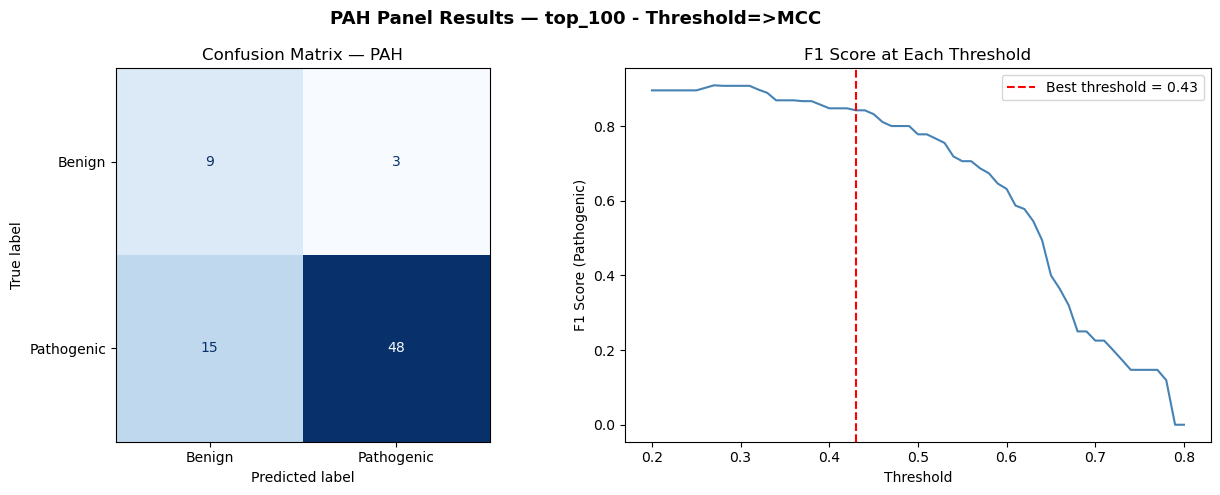

   Algorithm  : ExtraTrees
   Features   : 182
   Threshold  : 0.43
   F1 Score   : 0.9091


In [15]:
# ═══════════════════════════════════════════════════════
# PAH PANEL — Final Model Training
# ═══════════════════════════════════════════════════════

PAH_PATH = r"C:\Users\Sedra\Downloads\YARISMA_TRAIN_PAH.csv"   # ← change if needed
PANEL = "PAH"

df = pd.read_csv(PAH_PATH)
y = df['Label']
print(f"Loaded {PANEL}: {len(df)} rows")
print(f"Pathogenic (1): {(y==1).sum()} | Benign (0): {(y==0).sum()}")
print(f"⚠️  Warning: Only {(y==0).sum()} Benign samples — results may be unstable")

# ── Step 1: Find top AL_ columns ──
print("\nStep 1/4: Finding most important AL_ columns...")
X_full = build_features(df)
X_bal_sel, y_bal_sel = RandomUnderSampler(random_state=42).fit_resample(X_full, y)
quick_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
quick_rf.fit(X_bal_sel, y_bal_sel)
importances = pd.Series(quick_rf.feature_importances_, index=X_full.columns)
top_100 = importances.nlargest(100).index.tolist()
top_al_cols = [c for c in top_100 if c in al_cols]
print(f"  → Keeping {len(top_al_cols)} AL_ columns out of {len(al_cols)}")
print(f"  → (Using top 100 — safer for small dataset)")

# ── Step 2: Build feature matrix ──
print("\nStep 2/4: Building feature matrix...")
X = build_features(df, al_to_keep=top_al_cols)
print(f"  → {X.shape[1]} features total")

# ── Step 3: Cross-validation with 3 folds ──
print("\nStep 3/4: Cross-validation (3 folds — adjusted for small dataset)...")
models = {
    'ExtraTrees': ExtraTreesClassifier(
        n_estimators=300, max_depth=15,
        min_samples_leaf=3,
        class_weight='balanced', random_state=42, n_jobs=-1),
    'RandomForest': RandomForestClassifier(
        n_estimators=300, max_depth=15,
        min_samples_leaf=3,
        class_weight='balanced', random_state=42, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
results = {}

for name, clf in models.items():
    f1s, mccs, aucs = [], [], []
    for fold, (tr_idx, val_idx) in enumerate(cv.split(X, y)):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        X_tr_bal, y_tr_bal = RandomUnderSampler(
            random_state=fold).fit_resample(X_tr, y_tr)
        clf.fit(X_tr_bal, y_tr_bal)
        y_pred = clf.predict(X_val)
        y_prob = clf.predict_proba(X_val)[:, 1]
        f1s.append(f1_score(y_val, y_pred, pos_label=1))
        mccs.append(matthews_corrcoef(y_val, y_pred))
        aucs.append(roc_auc_score(y_val, y_prob))
    results[name] = {
        'F1': np.mean(f1s), 'MCC': np.mean(mccs), 'AUC': np.mean(aucs)}
    print(f"  {name}: F1={results[name]['F1']:.4f} | "
          f"MCC={results[name]['MCC']:.4f} | AUC={results[name]['AUC']:.4f}")

best_name = max(results, key=lambda k: results[k]['F1'])
print(f"\n  → Best model: {best_name}")

#----------------------------------------
''''
# ── Step 4: Threshold tuning ──
print("\nStep 4/4: Tuning classification threshold...")
X_tr2, X_hold, y_tr2, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=99)
X_tr2_bal, y_tr2_bal = RandomUnderSampler(
    random_state=42).fit_resample(X_tr2, y_tr2)

best_clf = models[best_name]
best_clf.fit(X_tr2_bal, y_tr2_bal)
probs = best_clf.predict_proba(X_hold)[:, 1]

best_thresh, best_f1 = 0.5, 0.0
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    score = f1_score(y_hold, preds_t, pos_label=1)
    if score > best_f1:
        best_f1, best_thresh = score, t

print(f"  → Best threshold: {best_thresh:.2f} | F1 (Pathogenic): {best_f1:.4f}")
y_final = (probs >= best_thresh).astype(int)'''

# ── FIXED Threshold tuning for small panels ──
# Use MCC instead of binary F1 to avoid "predict everything Pathogenic" trap

best_thresh, best_mcc = 0.5, -1.0
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    
    # Skip thresholds where model predicts only one class
    if len(set(preds_t)) < 2:
        continue
        
    mcc_t = matthews_corrcoef(y_hold, preds_t)
    if mcc_t > best_mcc:
        best_mcc, best_thresh = mcc_t, t

print(f"  → Best threshold: {best_thresh:.2f} | MCC: {best_mcc:.4f}")
y_final = (probs >= best_thresh).astype(int)

#---------------------------------------------------------

tn, fp, fn, tp = confusion_matrix(y_hold, y_final).ravel()
print("\n─── Competition Metrics on Hold-out Set ───")
print(f"  TP (Doğru Pozitif)  : {tp}")
print(f"  FP (Yanlış Pozitif) : {fp}")
print(f"  FN (Yanlış Negatif) : {fn}")
print(f"  TN (Doğru Negatif)  : {tn}")
print(f"  F1 Score            : {f1_score(y_hold, y_final, pos_label=1):.4f}")
print(f"  MCC                 : {matthews_corrcoef(y_hold, y_final):.4f}")
print(f"  Precision           : {tp/(tp+fp):.4f}")
print(f"  Recall (Sensitivity): {tp/(tp+fn):.4f}")
print(f"⚠️  Hold-out has only ~{(y_hold==0).sum()} Benign — interpret carefully")
print()
print(classification_report(y_hold, y_final,
      target_names=['Benign (0)', 'Pathogenic (1)']))

# ── Plots ──
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_hold, y_final)
ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Pathogenic']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix — {PANEL}')
f1_by_thresh = []
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    f1_by_thresh.append(f1_score(y_hold, preds_t, pos_label=1))
axes[1].plot(np.arange(0.20, 0.80, 0.01), f1_by_thresh, color='steelblue')
axes[1].axvline(x=best_thresh, color='red', linestyle='--',
                label=f'Best threshold = {best_thresh:.2f}')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('F1 Score (Pathogenic)')
axes[1].set_title('F1 Score at Each Threshold')
axes[1].legend()
plt.suptitle(f'{PANEL} Panel Results — top_100 - Threshold=>MCC', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

''''# ── Save ──
X_bal_final, y_bal_final = RandomUnderSampler(
    random_state=42).fit_resample(X, y)
best_clf.fit(X_bal_final, y_bal_final)
joblib.dump({
    'model': best_clf,
    'feature_cols': list(X.columns),
    'al_cols_used': top_al_cols,
    'threshold': best_thresh,
    'panel': PANEL
}, f'{PANEL}_model.pkl')

print(f"\n✅ {PANEL} model saved as {PANEL}_model.pkl")'''
print(f"   Algorithm  : {best_name}")
print(f"   Features   : {X.shape[1]}")
print(f"   Threshold  : {best_thresh:.2f}")
print(f"   F1 Score   : {best_f1:.4f}")

## CFTR - Threshold->F1

Loaded CFTR: 111 rows
Pathogenic (1): 90 | Benign (0): 21
⚠️  Warning: Only 21 Benign samples — very small dataset

Step 1/4: Finding most important AL_ columns...
  → Keeping 51 AL_ columns out of 334
  → (Using top 60 — safest for very small dataset)

Step 2/4: Building feature matrix...
  → 145 features total

Step 3/4: Cross-validation (3 folds)...
  ExtraTrees: F1=0.6524 | MCC=0.2553 | AUC=0.7524
  RandomForest: F1=0.8430 | MCC=0.4019 | AUC=0.8508

  → Best model: RandomForest

Step 4/4: Tuning classification threshold...
  → Best threshold: 0.24 | F1 (Pathogenic): 0.9268

─── Competition Metrics on Hold-out Set ───
  TP (Doğru Pozitif)  : 19
  FP (Yanlış Pozitif) : 3
  FN (Yanlış Negatif) : 0
  TN (Doğru Negatif)  : 1
  F1 Score            : 0.9268
  MCC                 : 0.4647
  Precision           : 0.8636
  Recall (Sensitivity): 1.0000
⚠️  Hold-out has only ~4 Benign — interpret carefully

                precision    recall  f1-score   support

    Benign (0)       1.00     

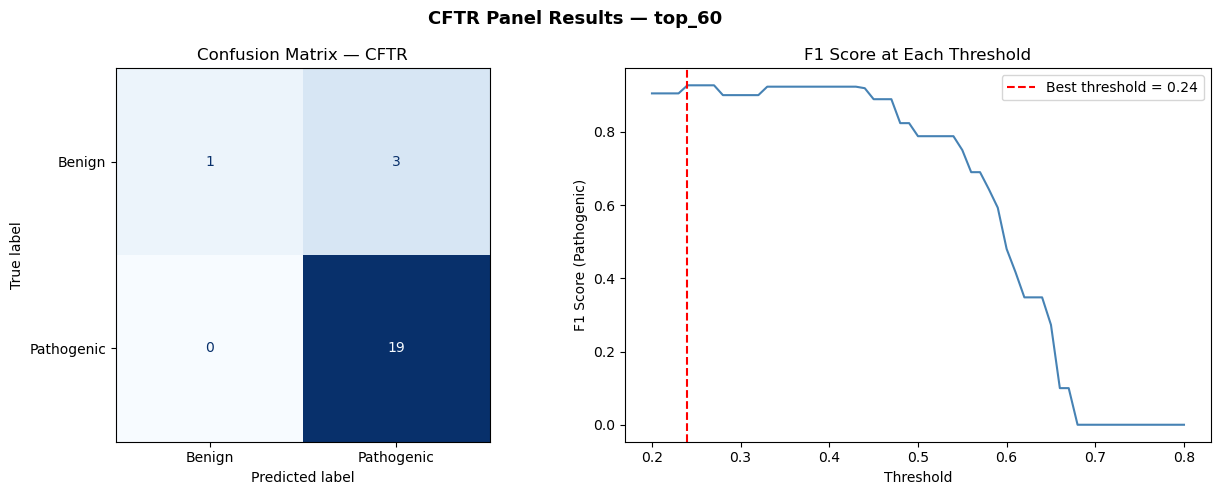

   Algorithm  : RandomForest
   Features   : 145
   Threshold  : 0.24
   F1 Score   : 0.9268


In [11]:
# ═══════════════════════════════════════════════════════
# CFTR PANEL — Final Model Training
# ═══════════════════════════════════════════════════════

CFTR_PATH = r"C:\Users\Sedra\Downloads\YARISMA_TRAIN_CFTR.csv"   # ← change if needed
PANEL = "CFTR"

df = pd.read_csv(CFTR_PATH)
y = df['Label']
print(f"Loaded {PANEL}: {len(df)} rows")
print(f"Pathogenic (1): {(y==1).sum()} | Benign (0): {(y==0).sum()}")
print(f"⚠️  Warning: Only {(y==0).sum()} Benign samples — very small dataset")

# ── Step 1: Find top AL_ columns ──
print("\nStep 1/4: Finding most important AL_ columns...")
X_full = build_features(df)
X_bal_sel, y_bal_sel = RandomUnderSampler(random_state=42).fit_resample(X_full, y)
quick_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
quick_rf.fit(X_bal_sel, y_bal_sel)
importances = pd.Series(quick_rf.feature_importances_, index=X_full.columns)
top_60 = importances.nlargest(60).index.tolist()
top_al_cols = [c for c in top_60 if c in al_cols]
print(f"  → Keeping {len(top_al_cols)} AL_ columns out of {len(al_cols)}")
print(f"  → (Using top 60 — safest for very small dataset)")

# ── Step 2: Build feature matrix ──
print("\nStep 2/4: Building feature matrix...")
X = build_features(df, al_to_keep=top_al_cols)
print(f"  → {X.shape[1]} features total")

# ── Step 3: Cross-validation with 3 folds ──
print("\nStep 3/4: Cross-validation (3 folds)...")
models = {
    'ExtraTrees': ExtraTreesClassifier(
        n_estimators=300, max_depth=8,
        min_samples_leaf=5,
        class_weight='balanced', random_state=42, n_jobs=-1),
    'RandomForest': RandomForestClassifier(
        n_estimators=300, max_depth=8,
        min_samples_leaf=5,
        class_weight='balanced', random_state=42, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
results = {}

for name, clf in models.items():
    f1s, mccs, aucs = [], [], []
    for fold, (tr_idx, val_idx) in enumerate(cv.split(X, y)):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        X_tr_bal, y_tr_bal = RandomUnderSampler(
            random_state=fold).fit_resample(X_tr, y_tr)
        clf.fit(X_tr_bal, y_tr_bal)
        y_pred = clf.predict(X_val)
        y_prob = clf.predict_proba(X_val)[:, 1]
        f1s.append(f1_score(y_val, y_pred, pos_label=1))
        mccs.append(matthews_corrcoef(y_val, y_pred))
        aucs.append(roc_auc_score(y_val, y_prob))
    results[name] = {
        'F1': np.mean(f1s), 'MCC': np.mean(mccs), 'AUC': np.mean(aucs)}
    print(f"  {name}: F1={results[name]['F1']:.4f} | "
          f"MCC={results[name]['MCC']:.4f} | AUC={results[name]['AUC']:.4f}")

best_name = max(results, key=lambda k: results[k]['F1'])
print(f"\n  → Best model: {best_name}")

# ── Step 4: Threshold tuning ──
print("\nStep 4/4: Tuning classification threshold...")
X_tr2, X_hold, y_tr2, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=99)
X_tr2_bal, y_tr2_bal = RandomUnderSampler(
    random_state=42).fit_resample(X_tr2, y_tr2)

best_clf = models[best_name]
best_clf.fit(X_tr2_bal, y_tr2_bal)
probs = best_clf.predict_proba(X_hold)[:, 1]

best_thresh, best_f1 = 0.5, 0.0
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    score = f1_score(y_hold, preds_t, pos_label=1)
    if score > best_f1:
        best_f1, best_thresh = score, t

print(f"  → Best threshold: {best_thresh:.2f} | F1 (Pathogenic): {best_f1:.4f}")
y_final = (probs >= best_thresh).astype(int)

tn, fp, fn, tp = confusion_matrix(y_hold, y_final).ravel()
print("\n─── Competition Metrics on Hold-out Set ───")
print(f"  TP (Doğru Pozitif)  : {tp}")
print(f"  FP (Yanlış Pozitif) : {fp}")
print(f"  FN (Yanlış Negatif) : {fn}")
print(f"  TN (Doğru Negatif)  : {tn}")
print(f"  F1 Score            : {f1_score(y_hold, y_final, pos_label=1):.4f}")
print(f"  MCC                 : {matthews_corrcoef(y_hold, y_final):.4f}")
print(f"  Precision           : {tp/(tp+fp):.4f}")
print(f"  Recall (Sensitivity): {tp/(tp+fn):.4f}")
print(f"⚠️  Hold-out has only ~{(y_hold==0).sum()} Benign — interpret carefully")
print()
print(classification_report(y_hold, y_final,
      target_names=['Benign (0)', 'Pathogenic (1)']))

# ── Plots ──
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_hold, y_final)
ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Pathogenic']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix — {PANEL}')
f1_by_thresh = []
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    f1_by_thresh.append(f1_score(y_hold, preds_t, pos_label=1))
axes[1].plot(np.arange(0.20, 0.80, 0.01), f1_by_thresh, color='steelblue')
axes[1].axvline(x=best_thresh, color='red', linestyle='--',
                label=f'Best threshold = {best_thresh:.2f}')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('F1 Score (Pathogenic)')
axes[1].set_title('F1 Score at Each Threshold')
axes[1].legend()
plt.suptitle(f'{PANEL} Panel Results — top_60', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

''''# ── Save ──
X_bal_final, y_bal_final = RandomUnderSampler(
    random_state=42).fit_resample(X, y)
best_clf.fit(X_bal_final, y_bal_final)
joblib.dump({
    'model': best_clf,
    'feature_cols': list(X.columns),
    'al_cols_used': top_al_cols,
    'threshold': best_thresh,
    'panel': PANEL
}, f'{PANEL}_model.pkl')

print(f"\n✅ {PANEL} model saved as {PANEL}_model.pkl")'''
print(f"   Algorithm  : {best_name}")
print(f"   Features   : {X.shape[1]}")
print(f"   Threshold  : {best_thresh:.2f}")
print(f"   F1 Score   : {best_f1:.4f}")